In [1]:
import numpy as np
import pandas as pd
import os

In [2]:
import tensorflow

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import optimizers
from tensorflow.keras import backend as K
import logging.config
from gym import  spaces
import gym
import json
import sys
import time

In [ ]:
class data_cls:
    def __init__(self, train_test, attack_map, **kwargs):
        self.train_test = train_test
        
        if self.train_test == 'train':
            self.train_path = r"" #upload train_ddqn file
        else:
            self.test_path = r"" #upload test_ddqn file

        self.attack_map =   attack_map 
        self.attack_types = list(attack_map.keys())
        
        self.loaded = False
        
    
    def get_batch(self, batch_size=100):
        
        if self.loaded is False:
            self._load_df()
            
        indexes = list(range(self.index,self.index+batch_size))    
        if max(indexes)>self.data_shape[0]-1:
            dif = max(indexes)-self.data_shape[0]
            indexes[len(indexes)-dif-1:len(indexes)] = list(range(dif+1))
            self.index=batch_size-dif
            batch = self.df.iloc[indexes]
        else: 
            batch = self.df.iloc[indexes]
            self.index += batch_size    
        
        map_type = pd.Series(index=self.attack_types,data=np.arange(len(self.attack_types))).to_dict()
        labels = batch[label_col].map(self.attack_map).map(map_type).values
        del(batch[label_col])
            
        return np.array(batch),labels
    
    def get_full(self):

        self._load_df()
        
        batch = self.df
        map_type = pd.Series(index=self.attack_types,data=np.arange(len(self.attack_types))).to_dict()
        labels = batch[label_col].map(self.attack_map).map(map_type).values
        
        del(batch[label_col])
        
        return np.array(batch), labels
    
    def get_shape(self):
        if self.loaded is False:
            self._load_df()
        
        self.data_shape = self.df.shape
        return self.data_shape
    
    def _load_df(self):
        if self.train_test == 'train':
            self.df = pd.read_csv(self.train_path) 
        else:
            self.df = pd.read_csv(self.test_path)
            
        self.index=np.random.randint(0,self.df.shape[0]-1,dtype=np.int32)
        self.loaded = True

In [17]:
class NetworkClassificationEnv(gym.Env, data_cls):
    def __init__(self,train_test, attack_map, **kwargs):
        data_cls.__init__(self,train_test, attack_map,**kwargs)
        self.data_shape = self.get_shape()
        self.batch_size = kwargs.get('batch_size', 1) 
        self.fails_episode = kwargs.get('fails_episode', 10) 
        
        # Gym spaces
        self.action_space = spaces.Discrete(len(self.attack_types))
        self.observation_space = spaces.Discrete(self.data_shape[0])
        
        self.observation_len = self.data_shape[1]-1
        
        self.counter = 0

    def _update_state(self):
        self.states,self.labels = self.get_batch(self.batch_size)
        

    def reset(self):
        self.states,self.labels = self.get_batch(self.batch_size)
        self.counter = 0
        
        return self.states
    def _get_rewards(self,actions):
        self.reward = 0
        if actions == self.labels:
            self.reward = 1
        else: 
            self.counter += 1

    def step(self,actions):
        self._get_rewards(actions)
            
        self._update_state()

        if self.counter >= self.fails_episode:
            self.done = True
        else:
            self.done = False
            
        return self.states, self.reward, self.done

In [18]:
import tensorflow as tf
from tensorflow.keras import backend as K

@tf.keras.utils.register_keras_serializable(package="Custom", name="huber_loss")
def huber_loss(y_true, y_pred, clip_value=1.0):
    assert clip_value > 0.0, "clip_value must be positive."

    x = y_true - y_pred
    
    # Handle the case when clip_value is infinity
    if np.isinf(clip_value):
        return 0.5 * tf.square(x)

    # Define condition for the quadratic part
    condition = tf.abs(x) < clip_value

    # Compute squared and linear losses
    squared_loss = 0.5 * tf.square(x)
    linear_loss = clip_value * (tf.abs(x) - 0.5 * clip_value)

    # Use TensorFlow's conditional logic to return the appropriate loss
    return tf.where(condition, squared_loss, linear_loss)


In [ ]:
# Check if the weights and model files exist
weights_path = r"" #DDQN_model.weights.h5 upload
json_path = r"" #DDQN_model.json upload

if os.path.exists(weights_path) and os.path.exists(json_path):
    print("Model files exist.")
else:
    print("Model files are missing.")

Model files exist.


In [20]:
import json
import numpy as np
import pandas as pd
from tensorflow.keras.models import model_from_json
import matplotlib.pyplot as plt

import itertools
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import  confusion_matrix

In [21]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [ ]:
with open(json_path) as jfile:
    model = model_from_json(json.load(jfile))
model.load_weights(weights_path)
label_dict = r"" #label_dict.json upload

with open(label_dict, "r") as f:
    label_dict = json.load(f)


model.compile(loss=huber_loss, optimizer="sgd")

env = NetworkClassificationEnv('test', label_dict) 

In [24]:
total_reward = 0

label_col = 'Label'
    
true_labels = np.zeros(len(env.attack_types),dtype=int)
estimated_labels = np.zeros(len(env.attack_types),dtype=int)
estimated_correct_labels = np.zeros(len(env.attack_types),dtype=int)

states, labels = env.get_full()
q = model.predict(states)
actions = np.argmax(q, axis=1)        


labs, true_labels = np.unique(labels, return_counts=True)

for indx,a in enumerate(actions):
    estimated_labels[a] +=1              
    if a == labels[indx]:
        total_reward += 1
        estimated_correct_labels[a] += 1


Accuracy = estimated_correct_labels / true_labels
Mismatch = estimated_labels - true_labels
print('\r\nTotal reward: {} | Number of samples: {} | Accuracy = {}%'.format(total_reward,
      len(states),float(100*total_reward/len(states))))
outputs_df = pd.DataFrame(index = env.attack_types,columns = ["Estimated","Correct","Total","Acuracy"])
for indx,att in enumerate(env.attack_types):
    outputs_df.iloc[indx].Estimated = estimated_labels[indx]
    outputs_df.iloc[indx].Correct = estimated_correct_labels[indx]
    outputs_df.iloc[indx].Total = true_labels[indx]
    outputs_df.iloc[indx].Acuracy = Accuracy[indx]*100
    outputs_df.iloc[indx].Mismatch = abs(Mismatch[indx])

11713/11713 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step

Total reward: 370363 | Number of samples: 374810 | Accuracy = 98.81353218964276%


In [25]:
outputs_df


,Estimated,Correct,Total,Acuracy
Benign,183722,183340,187405,97.830901
DDoS attack,191088,187023,187405,99.796163


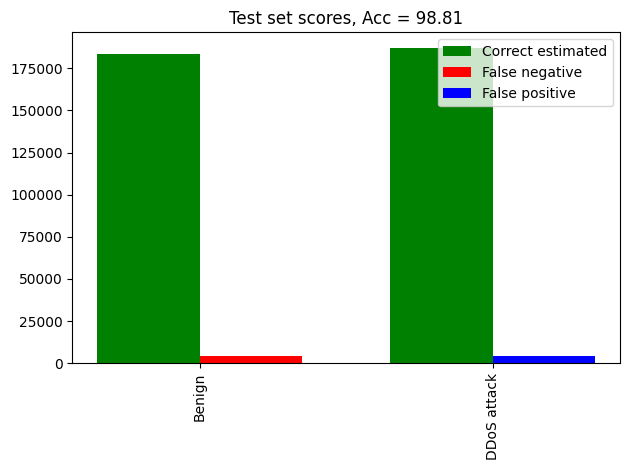

FileNotFoundError: [Errno 2] No such file or directory: 'results/ADFA_DDQN.svg'

<Figure size 640x480 with 0 Axes>

In [ ]:
fig, ax = plt.subplots()
width = 0.35
pos = np.arange(len(true_labels))
p1 = plt.bar(pos, estimated_correct_labels,width,color='g')
p1 = plt.bar(pos+width,
             (np.abs(estimated_correct_labels-true_labels)),width,
             color='r')
p2 = plt.bar(pos+width,np.abs(estimated_labels-estimated_correct_labels),width,
             bottom=(np.abs(estimated_correct_labels-true_labels)),
             color='b')


ax.set_xticks(pos+width/2)
ax.set_xticklabels(env.attack_types,rotation='vertical')

ax.set_title('Test set scores, Acc = {:.2f}'.format(100*total_reward/len(states)))
plt.legend(('Correct estimated','False negative','False positive'))
plt.tight_layout()
plt.show()

Performance measures on Test data
Accuracy =  0.9881
F1 =  0.9881
Precision_score =  0.9883
recall_score =  0.9881
Normalized confusion matrix
[[0.98 0.02]
 [0.   1.  ]]


<Figure size 640x480 with 0 Axes>

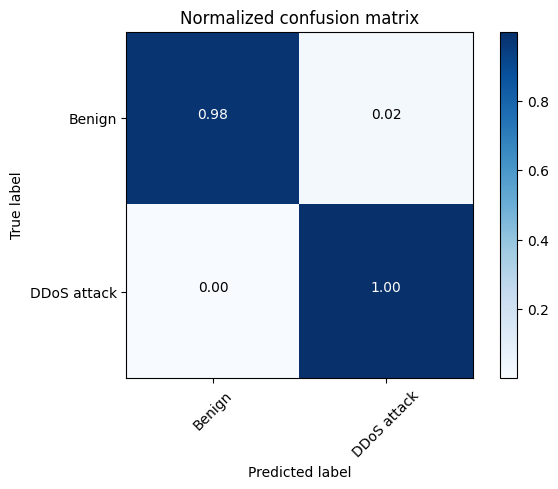

In [28]:
aggregated_data_test =labels

print('Performance measures on Test data')
print('Accuracy =  {:.4f}'.format(accuracy_score( aggregated_data_test,actions)))
print('F1 =  {:.4f}'.format(f1_score(aggregated_data_test,actions, average='weighted')))
print('Precision_score =  {:.4f}'.format(precision_score(aggregated_data_test,actions, average='weighted')))
print('recall_score =  {:.4f}'.format(recall_score(aggregated_data_test,actions, average='weighted')))

cnf_matrix = confusion_matrix(aggregated_data_test,actions)
np.set_printoptions(precision=2)
plt.figure()
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=env.attack_types, normalize=True,
                      title='Normalized confusion matrix')


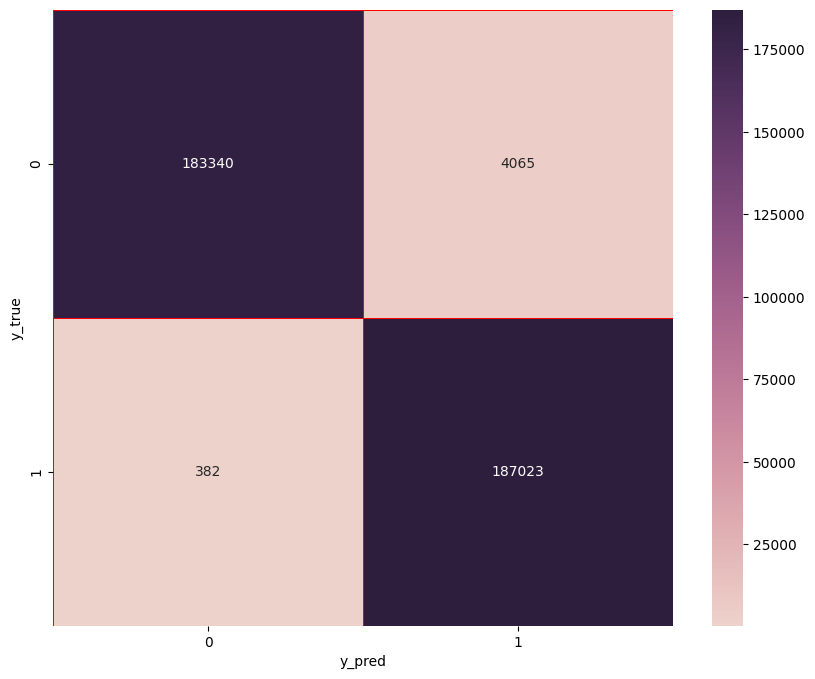

In [31]:
import seaborn as sns
cm=confusion_matrix(aggregated_data_test,actions)
f,ax=plt.subplots(figsize=(10,8))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax,cmap=sns.cubehelix_palette(as_cmap=True))
plt.xlabel("y_pred")
plt.ylabel("y_true")
plt.show()